# Phase 1 — Exploratory Data Analysis
**Goal:** Turn raw prices → insight about risk behavior

---

## Step 1 — Load & Inspect Data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf

plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

In [3]:
data = pd.read_csv("../data/prices.csv", index_col=0, parse_dates=True)

print(data.head())
print()
data.info()

                  ^GSPC        ^IXIC       AAPL       MSFT        JPM
Date                                                                 
2015-01-02  2058.199951  4726.810059  24.214895  39.767685  46.274319
2015-01-05  2020.579956  4652.569824  23.532726  39.401997  44.837734
2015-01-06  2002.609985  4592.740234  23.534933  38.823666  43.675125
2015-01-07  2025.900024  4650.470215  23.864948  39.316948  43.741776
2015-01-08  2062.139893  4736.189941  24.781891  40.473572  44.719246

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2516 entries, 2015-01-02 to 2024-12-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ^GSPC   2516 non-null   float64
 1   ^IXIC   2516 non-null   float64
 2   AAPL    2516 non-null   float64
 3   MSFT    2516 non-null   float64
 4   JPM     2516 non-null   float64
dtypes: float64(5)
memory usage: 117.9 KB


In [4]:
# Sanity checks
print("Missing values per ticker:")
print(data.isnull().sum())
print()
print("Date range:", data.index.min(), "→", data.index.max())
print("Tickers present:", list(data.columns))

Missing values per ticker:
^GSPC    0
^IXIC    0
AAPL     0
MSFT     0
JPM      0
dtype: int64

Date range: 2015-01-02 00:00:00 → 2024-12-31 00:00:00
Tickers present: ['^GSPC', '^IXIC', 'AAPL', 'MSFT', 'JPM']


---
## Step 2 — Compute Log Returns

**Why log returns?**
- Additive over time (arithmetic returns are not)
- Stationary — required for GARCH, VaR modelling
- Standard in quant finance

In [5]:
returns = np.log(data / data.shift(1)).dropna()

print("Returns shape:", returns.shape)
print()
print(returns.describe().round(4))

Returns shape: (2515, 5)

           ^GSPC      ^IXIC       AAPL       MSFT        JPM
count  2515.0000  2515.0000  2515.0000  2515.0000  2515.0000
mean      0.0004     0.0006     0.0009     0.0009     0.0006
std       0.0113     0.0135     0.0179     0.0171     0.0172
min      -0.1277    -0.1315    -0.1377    -0.1595    -0.1621
25%      -0.0038    -0.0051    -0.0074    -0.0068    -0.0072
50%       0.0006     0.0011     0.0010     0.0010     0.0006
75%       0.0057     0.0075     0.0101     0.0097     0.0087
max       0.0897     0.0893     0.1132     0.1329     0.1656


---
## Step 3 — Price vs Returns Visualization

**What to observe:**
- Prices → smooth trend
- Returns → noisy, mean-reverting
- Volatility clustering visible in return series

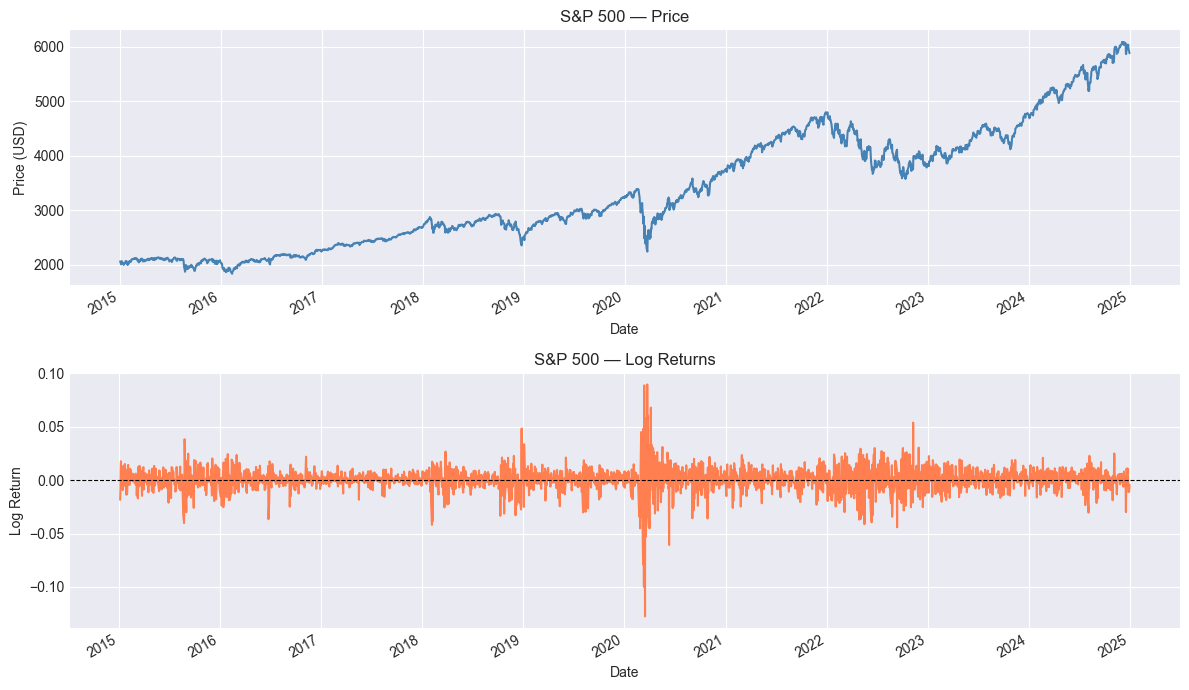

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

data["^GSPC"].plot(ax=axes[0], title="S&P 500 — Price", color='steelblue')
axes[0].set_ylabel("Price (USD)")

returns["^GSPC"].plot(ax=axes[1], title="S&P 500 — Log Returns", color='coral')
axes[1].set_ylabel("Log Return")
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')

plt.tight_layout()
plt.show()

---
## Step 4 — Distribution Analysis (Fat Tails)

**What to conclude:**
- Returns are NOT normally distributed
- High kurtosis → fat tails
- Normal-based VaR will **underestimate** real risk

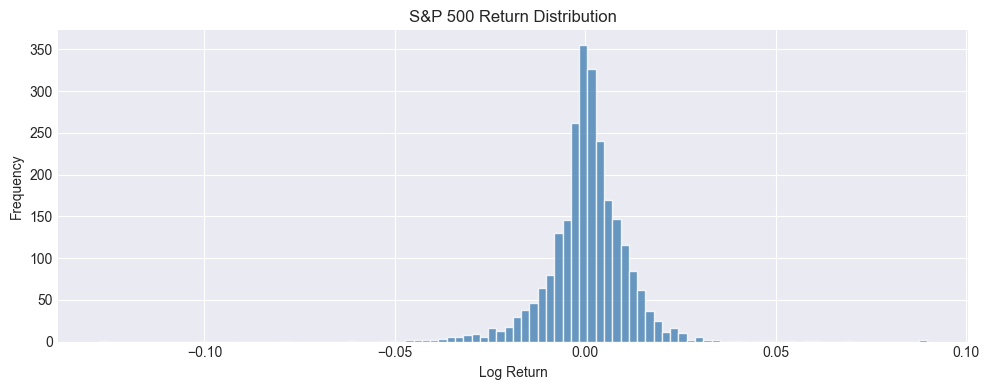

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))

returns["^GSPC"].hist(bins=100, ax=ax, color='steelblue', edgecolor='white', alpha=0.8)
ax.set_title("S&P 500 Return Distribution")
ax.set_xlabel("Log Return")
ax.set_ylabel("Frequency")
plt.tight_layout()
plt.show()

In [8]:
# Jarque-Bera normality test
stat, p = jarque_bera(returns["^GSPC"])
print(f"Jarque-Bera statistic : {stat:.2f}")
print(f"JB p-value            : {p:.6f}")
print(f"  → {'Reject' if p < 0.05 else 'Cannot reject'} normality at 5% significance")
print()

# Moments
print(f"Skewness  : {returns['^GSPC'].skew():.4f}  (negative = left-skewed, more extreme down-moves)")
print(f"Kurtosis  : {returns['^GSPC'].kurtosis():.4f}  (>3 = fat tails, normal = 0 excess)")

Jarque-Bera statistic : 26175.67
JB p-value            : 0.000000
  → Reject normality at 5% significance

Skewness  : -0.8104  (negative = left-skewed, more extreme down-moves)
Kurtosis  : 15.7551  (>3 = fat tails, normal = 0 excess)


---
## Step 5 — Autocorrelation (Hidden Structure)

**Key insight:**
- Returns → little autocorrelation (random-walk-like)
- Squared returns → strong autocorrelation (**volatility clustering**)
- This is exactly WHY GARCH models exist (Phase 2)

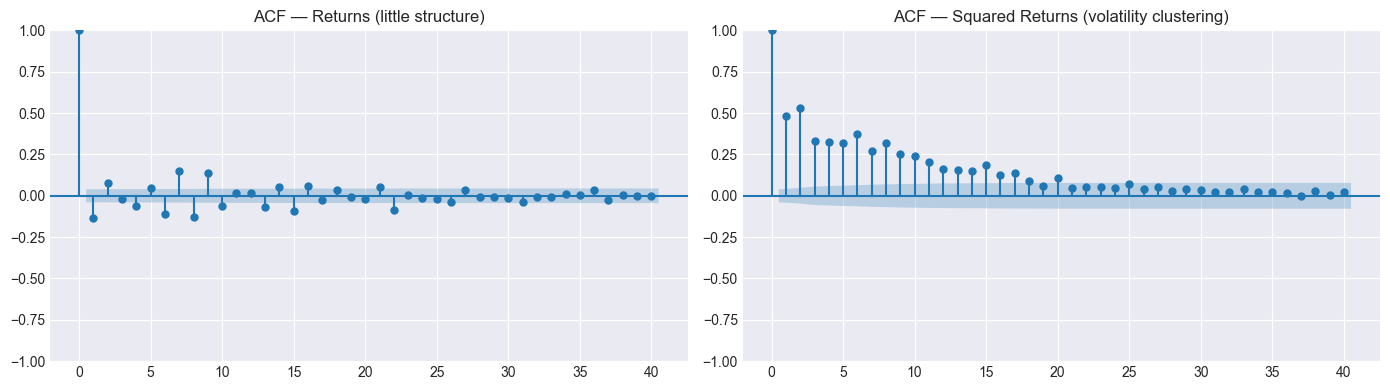

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

plot_acf(returns["^GSPC"], lags=40, ax=axes[0])
axes[0].set_title("ACF — Returns (little structure)")

plot_acf(returns["^GSPC"]**2, lags=40, ax=axes[1])
axes[1].set_title("ACF — Squared Returns (volatility clustering)")

plt.tight_layout()
plt.show()

---
## Step 6 — Rolling Volatility & Regime Detection

**What to observe:**
- Red clusters around 2020 (COVID crash) and 2022 (Fed tightening)
- Green clusters in calm bull-market periods
- This = **regime-switching behavior** → motivation for dynamic models

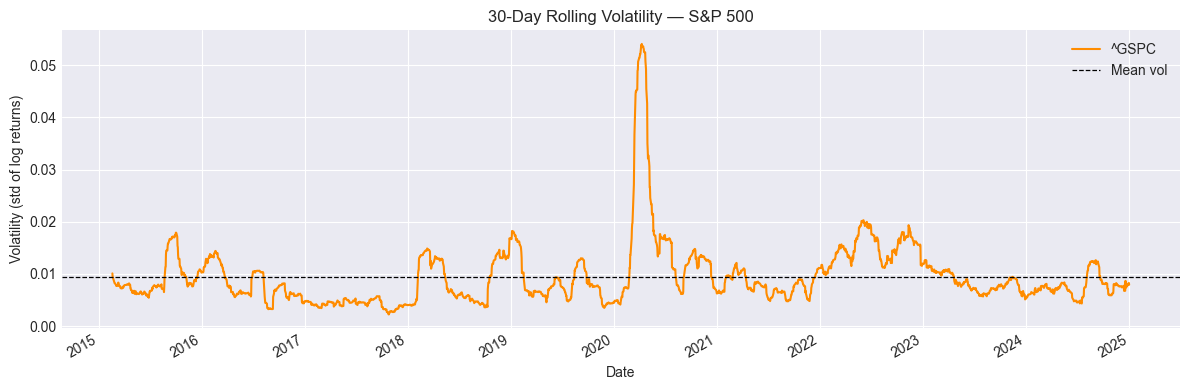

In [10]:
vol = returns["^GSPC"].rolling(30).std()

vol.plot(title="30-Day Rolling Volatility — S&P 500", figsize=(12, 4), color='darkorange')
plt.ylabel("Volatility (std of log returns)")
plt.axhline(vol.mean(), color='black', linestyle='--', linewidth=0.9, label='Mean vol')
plt.legend()
plt.tight_layout()
plt.show()

IndexingError: Unalignable boolean Series provided as indexer (index of the boolean Series and of the indexed object do not match).

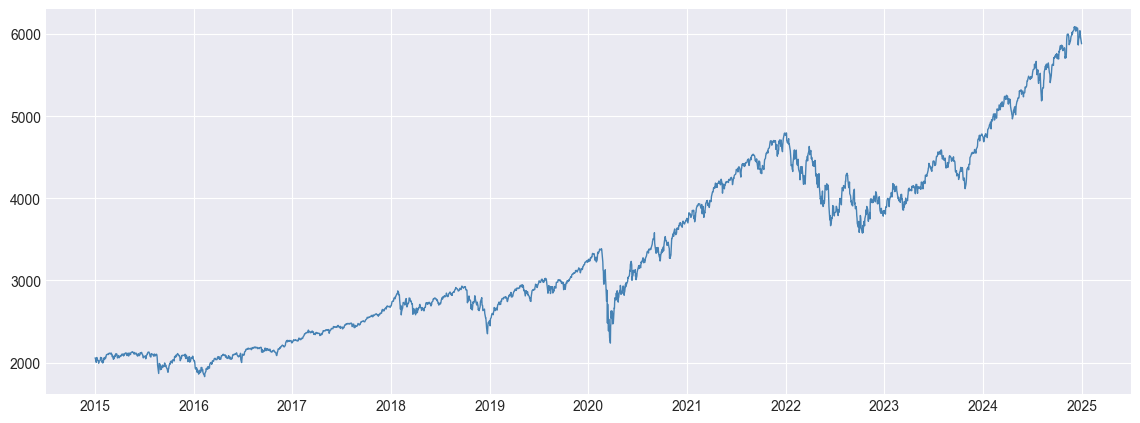

In [11]:
# Regime classification
high_vol = vol > vol.quantile(0.75)
low_vol  = vol < vol.quantile(0.25)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(data["^GSPC"], label="S&P 500 Price", color='steelblue', linewidth=1)

ax.scatter(vol.index[high_vol], data["^GSPC"].loc[high_vol],
           color='red', s=8, label="High Volatility Regime", zorder=3)

ax.scatter(vol.index[low_vol], data["^GSPC"].loc[low_vol],
           color='limegreen', s=8, label="Low Volatility Regime", zorder=3)

ax.set_title("Market Regimes — Volatility-Based Classification")
ax.set_ylabel("Price (USD)")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Summary stats by regime
regime = pd.Series("Normal", index=returns.index)
regime.loc[high_vol[high_vol].index] = "High Vol"
regime.loc[low_vol[low_vol].index]  = "Low Vol"

summary = returns["^GSPC"].groupby(regime).agg(
    count='count',
    mean_return='mean',
    std_return='std',
    min_return='min',
    max_return='max'
).round(4)

print("Return Statistics by Volatility Regime:")
print(summary)